# TaCo robustness suite v2 (single full run)
**Attach as inputs:** ISCXVPN pcaps, the TaCo code (with `pre-trained_TACO.pth`), and the updated `taco_robust.zip`.
**GPU on.** `FAST = False` (cell 1) is the full study and is designed to finish in about 8-9 hours: every attack stage has a wall-clock limit, each stage is wrapped so a failure never stops the next one, and a results zip is rewritten after every stage (download it any time from `/kaggle/working/taco_robust_results.zip`).

New in v2: (1) matched pre-trained vs from-scratch comparison, (2) linear probe + centred RQ1 on the pre-trained embedding, (3) identifier-masked retrain (IPs, ports, checksums zeroed) on both splits, plus parity filtering, per-stage time limits and single-threaded shards.

In [1]:
# ── CELL 1: knobs + setup ────────────────────────────────────────────
import os, sys, glob, shutil, subprocess, json, time, traceback, re
from pathlib import Path

FAST = False            # True = ~1.5 h smoke run; False = full study (~8-9 h)
N_SHARDS = 4            # parallel attack processes
EPOCHS = 12 if FAST else 60
SEEDS_TRAIN = [0] if FAST else [0, 1, 2]
RANDOM_SEEDS = [0] if FAST else [0, 1, 2]
BUDGETS = ["free(0B,0pkt)", "S(128B,1pkt)", "M(512B,2pkt)", "L(2KB,4pkt)"]
# wall-clock limit (seconds) for the attack phase of EACH stage (per shard, all shards run in parallel)
TL = dict(main=300, seeds=120, matched=150, imperson=120, capdisjoint=150, masked=150) if FAST else \
     dict(main=6000, seeds=1500, matched=2400, imperson=900, capdisjoint=2100, masked=2100)
MAX_FLOWS_FAST = 100 if FAST else 0
print("=" * 70); print("MODE:", "FAST (smoke run, 100 flows - NOT for the paper)" if FAST else "FULL STUDY"); print("=" * 70)

# Optional manual overrides (None = auto-discover under /kaggle/input)
RAW_PCAP_DIR = None
TACO_SRC = None         # folder containing fine-tune/, attack/, data/, pre-trained_TACO.pth
ROBUST_SRC = None       # folder that IS "robust" (contains pcap_ops.py)

def sh(cmd, check=True, **kw):
    print("$", cmd if isinstance(cmd, str) else " ".join(map(str, cmd)), flush=True)
    r = subprocess.run(cmd, shell=isinstance(cmd, str), **kw)
    if check and r.returncode != 0:
        raise RuntimeError(f"command failed (exit {r.returncode})")
    return r

sh([sys.executable, "-m", "pip", "install", "-q", "scapy", "tqdm", "scikit-learn", "matplotlib", "pandas", "pytest", "timm==0.3.2"])

# timm==0.3.2 imports torch._six, which modern torch removed -> tiny shim
import torch
six = os.path.join(os.path.dirname(torch.__file__), "_six.py")
if not os.path.exists(six):
    open(six, "w").write("import collections.abc\ncontainer_abcs = collections.abc\nstring_classes = (str, bytes)\n"
                         "int_classes = int\ninf = float('inf')\nnan = float('nan')\n")
    print("wrote torch._six shim")

def first(pattern):
    hits = sorted(glob.glob(pattern, recursive=True))
    return hits[0] if hits else None

if RAW_PCAP_DIR is None:
    pcaps = glob.glob("/kaggle/input/**/*.pcap", recursive=True)
    assert pcaps, "No .pcap files under /kaggle/input - attach the ISCXVPN dataset"
    RAW_PCAP_DIR = os.path.commonpath([os.path.dirname(p) for p in pcaps])
if TACO_SRC is None:
    m = first("/kaggle/input/**/models_TACO.py")
    assert m, "TaCo code not found under /kaggle/input"
    TACO_SRC = str(Path(m).parent.parent)
if ROBUST_SRC is None:
    z = first("/kaggle/input/**/taco_robust.zip") or first("/kaggle/input/**/robust.zip")
    if z:
        shutil.rmtree("/kaggle/working/_robust_zip", ignore_errors=True)
        shutil.unpack_archive(z, "/kaggle/working/_robust_zip")
        ROBUST_SRC = "/kaggle/working/_robust_zip/robust"
    else:
        p = first("/kaggle/input/**/pcap_ops.py")
        assert p, "robust/ package not found under /kaggle/input"
        ROBUST_SRC = str(Path(p).parent)
assert (Path(ROBUST_SRC) / "linear_probe.py").exists(), "robust/ is the OLD version - attach the updated taco_robust.zip"
print("RAW_PCAP_DIR:", RAW_PCAP_DIR, "| pcaps:", len(glob.glob(RAW_PCAP_DIR + "/**/*.pcap", recursive=True)))
print("TACO_SRC    :", TACO_SRC)
print("ROBUST_SRC  :", ROBUST_SRC)

REPO = Path("/kaggle/working/TaCo")
if REPO.exists():
    shutil.rmtree(REPO)
shutil.copytree(TACO_SRC, REPO)
shutil.copytree(ROBUST_SRC, REPO / "robust", dirs_exist_ok=True)
tm_md = Path(ROBUST_SRC).parent / "THREAT_MODEL.md"
if tm_md.exists():
    shutil.copy(tm_md, REPO / "THREAT_MODEL.md")

# PyTorch >= 2.6 defaults torch.load(weights_only=True), which rejects the argparse.Namespace stored in
# TaCo checkpoints.  These are our own checkpoints, so load them with weights_only=False.
patched = 0
for f in REPO.rglob("*.py"):
    src = f.read_text()
    new_src = re.sub(r"torch\.load\(([^()]*(?:\([^()]*\)[^()]*)*)\)",
                     lambda m: m.group(0) if "weights_only" in m.group(1)
                     else "torch.load(" + m.group(1) + ", weights_only=False)", src)
    if new_src != src:
        f.write_text(new_src); patched += 1
print("patched torch.load in", patched, "files")

os.chdir(REPO)
sys.path.insert(0, str(REPO))
PRETRAINED = str(REPO / "pre-trained_TACO.pth")
assert Path(PRETRAINED).exists(), "pre-trained_TACO.pth missing from the TaCo input"
# one thread per process: 4 shards x multi-threaded torch/numpy would oversubscribe the CPU
ENV = dict(os.environ, PYTHONPATH=str(REPO), OMP_NUM_THREADS="1", MKL_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1")
OUT = Path("/kaggle/working/results"); OUT.mkdir(exist_ok=True, parents=True)
CK = {}          # name -> checkpoint path
STAGE_LOG = []

def bundle():
    tmp = "/kaggle/working/_bundle"
    shutil.rmtree(tmp, ignore_errors=True)
    shutil.copytree(OUT, tmp, ignore=shutil.ignore_patterns("*.pth", "records_*.csv"))
    shutil.make_archive("/kaggle/working/taco_robust_results", "zip", tmp)

def stage(name):
    """Run the decorated function now; a failure is printed and logged but never stops the notebook."""
    def deco(fn):
        t0 = time.time()
        print("\n" + "=" * 18, name, "=" * 18, flush=True)
        try:
            fn(); status = "ok"
        except Exception:
            traceback.print_exc(); status = "FAILED"
        STAGE_LOG.append((name, status, round(time.time() - t0)))
        print(f"[{name}] {status} in {time.time() - t0:.0f}s", flush=True)
        try: bundle()
        except Exception as e: print("bundle failed:", e)
        return fn
    return deco

MODE: FULL STUDY
$ /usr/bin/python3 -m pip install -q scapy tqdm scikit-learn matplotlib pandas pytest timm==0.3.2
wrote torch._six shim
RAW_PCAP_DIR: /kaggle/input/datasets/cs23b2013/iscxvpn | pcaps: 102
TACO_SRC    : /kaggle/input/models/me23b1021/taco/pytorch/default/1/TaCo
ROBUST_SRC  : /kaggle/input/models/me23b1021/taco-robust/pytorch/default/1/robust
patched torch.load in 5 files


In [2]:
# ── CELL 2: per-flow pcaps (critical step: failure stops here) ─────────
FLOWS = "/kaggle/working/flows_by_class"
sh(f'python data/split_flows_and_bucket.py --input_dir "{RAW_PCAP_DIR}" --output_dir "{FLOWS}" '
   f'--packets_per_flow 10 --min_packets_per_flow 5 --max_flows_per_class 500 --test_ratio 0.2', env=ENV)
CLASSES = sorted(p.name for p in (Path(FLOWS) / "train").iterdir())
NB_CLASSES = len(CLASSES)
print(NB_CLASSES, CLASSES)

$ python data/split_flows_and_bucket.py --input_dir "/kaggle/input/datasets/cs23b2013/iscxvpn" --output_dir "/kaggle/working/flows_by_class" --packets_per_flow 10 --min_packets_per_flow 5 --max_flows_per_class 500 --test_ratio 0.2
Found 102 pcap file(s) under /kaggle/input/datasets/cs23b2013/iscxvpn
[chat         ] splitting aim_chat_3a.pcap ...
    -> 13 flows (>= 5 packets each)
[chat         ] splitting aim_chat_3b.pcap ...
    -> 16 flows (>= 5 packets each)
[email        ] splitting email1a.pcap ...
    -> 140 flows (>= 5 packets each)
[email        ] splitting email1b.pcap ...
    -> 145 flows (>= 5 packets each)
[email        ] splitting email2a.pcap ...
    -> 98 flows (>= 5 packets each)
[email        ] splitting email2b.pcap ...
    -> 98 flows (>= 5 packets each)
[voip         ] splitting facebook_audio1a.pcap ...
    -> 36 flows (>= 5 packets each)
[voip         ] splitting facebook_audio2a.pcap ...
    -> 49 flows (>= 5 packets each)
[chat         ] splitting facebook_chat

In [3]:
# ── CELL 3: MFR images, capture-disjoint split, identifier-masked copies ──
MFR = "/kaggle/working/mfr_dataset"
sys.path.insert(0, str(REPO / "data"))
from data_process import MFR_generator
MFR_generator(FLOWS, MFR)

FLOWS_CD, MFR_CD = FLOWS + "_capdisjoint", MFR + "_capdisjoint"
sh(f'python -m robust.make_capture_split --flows_root "{FLOWS}" --out "{FLOWS_CD}"', env=ENV)
print(open(Path(FLOWS_CD) / "split_report.json").read())
MFR_generator(FLOWS_CD, MFR_CD)
CLASSES_CD = sorted(p.name for p in (Path(FLOWS_CD) / "train").iterdir())
NB_CD = len(CLASSES_CD)
print("capture-disjoint classes:", NB_CD, CLASSES_CD)

MFR_M, MFR_CD_M = MFR + "_masked", MFR_CD + "_masked"
sh(f'python -m robust.mask_dataset --src "{MFR}" --dst "{MFR_M}"', env=ENV)
sh(f'python -m robust.mask_dataset --src "{MFR_CD}" --dst "{MFR_CD_M}"', env=ENV)
MASK_IP = "ip_src,ip_dst,ip_checksum,l4_checksum"          # addresses only (ports kept); checksums leak the IPs
MFR_MIP = MFR + "_maskedip"
sh(f'python -m robust.mask_dataset --src "{MFR}" --dst "{MFR_MIP}" --fields "{MASK_IP}"', env=ENV)
for sp in ("train", "test"):
    print(sp, {c: len(list((Path(MFR) / sp / c).glob("*.png"))) for c in CLASSES})

100%|██████████| 2750/2750 [00:06<00:00, 400.73it/s]

$ python -m robust.make_capture_split --flows_root "/kaggle/working/flows_by_class" --out "/kaggle/working/flows_by_class_capdisjoint"


[chat          ] train= 397 test= 103  ['vpn_facebook_chat1a', 'vpn_aim_chat1a', 'aim_chat_3a', 'vpn_skype_chat1a', 'facebook_chat_4a', 'vpn_icq_chat1a', 'vpn_aim_chat1b', 'facebook_chat_4b', 'icq_chat_3a', 'vpn_skype_chat1b']
[email         ] train= 309 test= 191  ['email2a', 'email1a']
[file_transfer ] train= 382 test= 118  ['vpn_ftps_B', 'vpn_skype_files1a']
[skip] class p2p: only one capture (vpn_bittorrent); no capture-disjoint split possible
[streaming     ] train= 379 test= 121  ['vpn_youtube_A', 'youtube5', 'spotify2', 'youtube3', 'vimeo1']
[voip          ] train= 393 test= 107  ['facebook_audio1a', 'hangouts_audio2a', 'skype_audio2a', 'vpn_skype_audio2', 'voipbuster_4a']
{
  "chat": {
    "status": "ok",
    "test_captures": [
      "vpn_facebook_chat1a",
      "vpn_aim_chat1a",
      "aim_chat_3a",
      "vpn_skype_chat1a",
      "facebook_chat_4a",
      "vpn_icq_chat1a",
      "vpn_aim_chat1b",
      "facebook_chat_4b",
      "icq_chat_3a",
      "vpn_skype_chat1b"
    ],
 

100%|██████████| 2500/2500 [00:06<00:00, 394.82it/s]

capture-disjoint classes: 5 ['chat', 'email', 'file_transfer', 'streaming', 'voip']
$ python -m robust.mask_dataset --src "/kaggle/working/mfr_dataset" --dst "/kaggle/working/mfr_dataset_masked"


masked 2750 images (ip_src,ip_dst,l4_sport,l4_dport,ip_checksum,l4_checksum) -> /kaggle/working/mfr_dataset_masked
$ python -m robust.mask_dataset --src "/kaggle/working/mfr_dataset_capdisjoint" --dst "/kaggle/working/mfr_dataset_capdisjoint_masked"
masked 2500 images (ip_src,ip_dst,l4_sport,l4_dport,ip_checksum,l4_checksum) -> /kaggle/working/mfr_dataset_capdisjoint_masked
$ python -m robust.mask_dataset --src "/kaggle/working/mfr_dataset" --dst "/kaggle/working/mfr_dataset_maskedip" --fields "ip_src,ip_dst,ip_checksum,l4_checksum"
masked 2750 images (ip_src,ip_dst,ip_checksum,l4_checksum) -> /kaggle/working/mfr_dataset_maskedip
train {'chat': 400, 'email': 400, 'file_transfer': 400, 'p2p': 200, 'streaming': 400, 'voip': 400}
test {'chat': 100, 'email': 100, 'file_transfer': 100, 'p2p': 50, 'streaming': 100, 'voip': 100}


In [4]:
# ── CELL 4: unit tests ────────────────────────────────────────────────
@stage("unit tests")
def _():
    sh("python -m pytest robust/tests -q", env=ENV)


================== unit tests ==================
$ python -m pytest robust/tests -q
................                                                         [100%]
16 passed in 5.00s
[unit tests] ok in 14s


In [5]:
# ── CELL 5: fine-tuning (all models use the SAME recipe and epochs) ─────
def finetune(tag, seed, mfr_dir, nb, pretrained):
    out = f"/kaggle/working/ft/{tag}"
    if not glob.glob(out + "/checkpoint-*.pth"):
        ft = f'--finetune "{pretrained}"' if pretrained else ""
        sh(f'cd fine-tune && python finetune.py --model TaCo_classifier {ft} --data_path "{mfr_dir}" '
           f'--nb_classes {nb} --output_dir "{out}" --log_dir "{out}/logs" --epochs {EPOCHS} '
           f'--batch_size 64 --num_workers 2 --seed {seed} --device cuda 2>&1 | tail -n 12', env=ENV, check=False)
    c = glob.glob(out + "/checkpoint-*.pth")
    assert c, f"no checkpoint produced for {tag}"
    return max(c, key=lambda p: int(Path(p).stem.split("-")[-1]))      # last new-best epoch (validation-selected)

JOBS = [(f"pre_seed{s}", s, MFR, NB_CLASSES, PRETRAINED) for s in SEEDS_TRAIN] + [
    ("scratch_seed0", 0, MFR, NB_CLASSES, None),                 # matched baseline: no contrastive pre-training
    ("pre_cd", 0, MFR_CD, NB_CD, PRETRAINED),                    # capture-disjoint split
    ("pre_masked", 0, MFR_M, NB_CLASSES, PRETRAINED),            # IPs/ports/checksums zeroed
    ("pre_masked_cd", 0, MFR_CD_M, NB_CD, PRETRAINED),           # masked + capture-disjoint
    ("pre_masked_ip", 0, MFR_MIP, NB_CLASSES, PRETRAINED),       # only IP addresses (+dependent checksums) masked
]
for tag, seed, mfr_dir, nb, pre in JOBS:
    @stage(f"finetune {tag}")
    def _():
        CK[tag] = finetune(tag, seed, mfr_dir, nb, pre)
print(CK)


================== finetune pre_seed0 ==================
$ cd fine-tune && python finetune.py --model TaCo_classifier --finetune "/kaggle/working/TaCo/pre-trained_TACO.pth" --data_path "/kaggle/working/mfr_dataset" --nb_classes 6 --output_dir "/kaggle/working/ft/pre_seed0" --log_dir "/kaggle/working/ft/pre_seed0/logs" --epochs 60 --batch_size 64 --num_workers 2 --seed 0 --device cuda 2>&1 | tail -n 12
[15:27:14.126280] Max F1: 0.9258
[15:27:14.126283] Max Precision: 0.9289
[15:27:14.126287] Max Recall: 0.9250
[15:27:14.126337] Training time 0:04:02
/kaggle/working/TaCo/fine-tune/engine.py:133: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
[15:27:14.296209] Test:  [0/9]  loss: 0.3590 (0.3590)  acc1: 0.8906 (0.8906)  acc5: 1.0000 (1.0000)  eta: 0:00:01  time: 0.1367  data: 0.0968  max mem: 1988
[15:27:14.645399] Test:  [8/9]  loss: 0.3167 (0.3368)  acc1: 0.9211 (0.9091)  acc5: 

In [6]:
# ── CELL 6: change 2 - is the pre-trained embedding class-informative? ──
@stage("linear probe (pretrained vs random-init vs fine-tuned)")
def _():
    sh(f'python -m robust.linear_probe --mfr_root "{MFR}" --pretrained "{PRETRAINED}" --ckpt "{CK["pre_seed0"]}" '
       f'--nb_classes {NB_CLASSES} --out "{OUT}/linear_probe" --device cuda', env=ENV)


================== linear probe (pretrained vs random-init vs fine-tuned) ==================
$ python -m robust.linear_probe --mfr_root "/kaggle/working/mfr_dataset" --pretrained "/kaggle/working/TaCo/pre-trained_TACO.pth" --ckpt "/kaggle/working/ft/pre_seed0/checkpoint-38.pth" --nb_classes 6 --out "/kaggle/working/results/linear_probe" --device cuda
train 2200  test 550  classes ['chat', 'email', 'file_transfer', 'p2p', 'streaming', 'voip']
pretrained {
 "probe_acc": 0.7181818181818181,
 "probe_ci": [
  0.6791695111119238,
  0.7541673852136681
 ],
 "probe_macro_f1": 0.7395511702588052,
 "knn5_acc": 0.610909090909091,
 "auc_raw_cosine": 0.542430918344562,
 "auc_centered_cosine": 0.5521314189797882,
 "auc_whitened_cosine": 0.551826567545717,
 "mean_raw_cosine": 0.9419816136360168
}
random_init {
 "probe_acc": 0.47454545454545455,
 "probe_ci": [
  0.4331334734535002,
  0.5163105553085141
 ],
 "probe_macro_f1": 0.4932162978848622,
 "knn5_acc": 0.4781818181818182,
 "auc_raw_cosine": 0.518

In [7]:
# ── CELL 7: sharded attack runner ─────────────────────────────────────
def run_eval(flows, ckpts, out_dir, nb, goal="evasion", attacks=("random", "greedy"), seeds=(0,),
             budgets=None, pgd=False, mfr_root="", common_with=(), time_limit=1800, mask=False,
             max_flows=None):
    budgets = budgets or BUDGETS
    max_flows = MAX_FLOWS_FAST if max_flows is None else max_flows
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    env = dict(ENV)
    if mask:
        env["ROBUST_MASK_FIELDS"] = "default" if mask is True else str(mask)
    procs = []
    for i in range(N_SHARDS):
        cmd = [sys.executable, "-m", "robust.eval_attacks", "--flows_root", flows, "--ckpts", *ckpts,
               "--nb_classes", str(nb), "--attacks", *attacks, "--budgets", *budgets,
               "--seeds", *[str(s) for s in seeds], "--goal", goal, "--max_flows", str(max_flows),
               "--shard", f"{i}/{N_SHARDS}", "--time_limit_s", str(time_limit),
               "--out", str(out_dir), "--device", "cuda"]
        if mfr_root: cmd += ["--mfr_root", mfr_root]
        if common_with: cmd += ["--common_with", *common_with]
        if (not pgd) or i != 0: cmd += ["--no_pgd"]          # feature-space PGD reference: shard 0 only
        log = open(out_dir / f"shard{i}.log", "w")
        procs.append((subprocess.Popen(cmd, stdout=log, stderr=subprocess.STDOUT, env=env), log))
    t0 = time.time()
    for p, log in procs:
        p.wait(); log.close()
    codes = [p.returncode for p, _ in procs]
    print(f"attacks finished in {time.time() - t0:.0f}s, return codes {codes}")
    for i, c in enumerate(codes):
        if c != 0:
            print(f"--- shard{i} log tail ---\n" + open(out_dir / f"shard{i}.log").read()[-1800:])
    print(open(out_dir / "shard0.log").read()[:900])
    sh([sys.executable, "-m", "robust.merge_shards", "--dir", str(out_dir)], env=env)

In [8]:
# ── CELL 8: HEADLINE - evasion, pre-trained model (random x3 seeds, greedy, gradient, PGD reference) ──
@stage("evasion main")
def _():
    run_eval(FLOWS, [CK["pre_seed0"]], OUT / "evasion", NB_CLASSES, "evasion",
             attacks=("random", "greedy", "gradient"), seeds=RANDOM_SEEDS, pgd=True, mfr_root=MFR,
             time_limit=TL["main"])

@stage("evasion other training seeds (greedy only)")
def _():
    extra = [CK[f"pre_seed{s}"] for s in SEEDS_TRAIN if s != 0]
    if extra:
        run_eval(FLOWS, extra, OUT / "evasion_seeds12", NB_CLASSES, "evasion", attacks=("greedy",),
                 seeds=(0,), mfr_root=MFR, time_limit=TL["seeds"])


================== evasion main ==================
attacks finished in 3135s, return codes [0, 0, 0, 0]
[mask] fields = none
[data] test: 550 flows, 6 classes, 68 captures
[parity] mismatch skype_chat1a_flow53.pcap: 70 bytes differ, first at (row,col)=[2, 0] png=126 mem=0
[parity] in-memory MFR == PNG for 549/550 flows (99.818%)
[parity] kept 549/550 flows
[model 0] clean acc 499/549 = 0.9089  (95% Wilson 0.8819-0.9302)
  25/125 flows done (526s)
  50/125 flows done (1098s)
  75/125 flows done (1769s)
  100/125 flows done (2335s)
  125/125 flows done (2948s)

=== ASR (mean over flows, 95% bootstrap CI over flows) ===
model0 random             free(0B,0pkt)    0.139 [0.085, 0.200] n=125
model0 random             S(128B,1pkt)     0.173 [0.115, 0.237] n=125
model0 random             M(512B,2pkt)     0.160 [0.101, 0.221] n=125
model0 random             L(2KB,4pkt)      0.149 [0.093, 0.211] n=125
model0 greedy             free(0B,0pkt)    0.128 [0.072, 0.192] n=125
model0 greedy           

/kaggle/working/TaCo/robust/merge_shards.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["ok"] = df["success"] & (df["valid"].fillna(True).astype(bool))
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validity_rate_of_successes=float(g[g.success]["valid"].fillna(True).astype(bool).mean())
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) inste


greedy minus random (paired bootstrap):
 model        budget  n_flows  greedy  random   diff     lo    hi  significant
     0   L(2KB,4pkt)      499   0.244   0.166  0.079  0.057 0.102         True
     0  M(512B,2pkt)      499   0.232   0.166  0.066  0.046 0.089         True
     0  S(128B,1pkt)      499   0.198   0.172  0.027  0.014 0.040         True
     0 free(0B,0pkt)      499   0.138   0.143 -0.005 -0.013 0.002        False
 model            attack                         budget      asr       lo       hi  n_flows  robust_acc_all_flows
     0          gradient                    L(2KB,4pkt) 0.200401 0.166333 0.236473      499              0.726776
     0          gradient                   M(512B,2pkt) 0.190381 0.156313 0.224449      499              0.735883
     0          gradient                   S(128B,1pkt) 0.174349 0.142285 0.208417      499              0.750455
     0          gradient                  free(0B,0pkt) 0.138277 0.108216 0.168337      499              0.7

/kaggle/working/TaCo/robust/merge_shards.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["ok"] = df["success"] & (df["valid"].fillna(True).astype(bool))
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validity_rate_of_successes=float(g[g.success]["valid"].fillna(True).astype(bool).mean())
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) inste

 model attack        budget      asr       lo       hi  n_flows  robust_acc_all_flows
     0 greedy   L(2KB,4pkt) 0.257937 0.218254 0.295635      504              0.681239
     0 greedy  M(512B,2pkt) 0.251984 0.214286 0.289683      504              0.686703
     0 greedy  S(128B,1pkt) 0.230159 0.194444 0.267857      504              0.706740
     0 greedy free(0B,0pkt) 0.148810 0.119048 0.180556      504              0.781421
     1 greedy   L(2KB,4pkt) 0.224852 0.189349 0.262327      507              0.715847
     1 greedy  M(512B,2pkt) 0.216963 0.183432 0.254438      507              0.723133
     1 greedy  S(128B,1pkt) 0.213018 0.177515 0.250493      507              0.726776
     1 greedy free(0B,0pkt) 0.132150 0.104536 0.161736      507              0.801457
[evasion other training seeds (greedy only)] ok in 797s


In [9]:
# ── CELL 9: change 1 - matched pre-trained vs scratch (same flows, same epochs, paired CI) ──
@stage("matched: pretrained vs scratch")
def _():
    run_eval(FLOWS, [CK["pre_seed0"]], OUT / "matched_pre", NB_CLASSES, attacks=("random", "greedy"), seeds=(0,),
             mfr_root=MFR, common_with=[CK["scratch_seed0"]], time_limit=TL["matched"])
    run_eval(FLOWS, [CK["scratch_seed0"]], OUT / "matched_scratch", NB_CLASSES, attacks=("random", "greedy"),
             seeds=(0,), mfr_root=MFR, common_with=[CK["pre_seed0"]], time_limit=TL["matched"])
    sh([sys.executable, "-m", "robust.paired_compare", "--a", str(OUT / "matched_pre"),
        "--b", str(OUT / "matched_scratch"), "--name_a", "pretrained", "--name_b", "scratch",
        "--out", str(OUT / "paired_pre_vs_scratch.json")], env=ENV)


================== matched: pretrained vs scratch ==================
attacks finished in 1238s, return codes [0, 0, 0, 0]
[mask] fields = none
[data] test: 550 flows, 6 classes, 68 captures
[parity] mismatch skype_chat1a_flow53.pcap: 70 bytes differ, first at (row,col)=[2, 0] png=126 mem=0
[parity] in-memory MFR == PNG for 549/550 flows (99.818%)
[parity] kept 549/550 flows
[model 0] clean acc 499/549 = 0.9089  (95% Wilson 0.8819-0.9302)
  25/107 flows done (258s)
  50/107 flows done (550s)
  75/107 flows done (862s)
  100/107 flows done (1159s)

=== ASR (mean over flows, 95% bootstrap CI over flows) ===
model0 random             free(0B,0pkt)    0.103 [0.047, 0.168] n=107
model0 random             S(128B,1pkt)     0.112 [0.056, 0.178] n=107
model0 random             M(512B,2pkt)     0.084 [0.037, 0.140] n=107
model0 random             L(2KB,4pkt)      0.093 [0.047, 0.150] n=107
model0 greedy             free(0B,0pkt)    0.093 [0.037, 0.150] n=107
model0 greedy             S(128B,1pkt

/kaggle/working/TaCo/robust/merge_shards.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["ok"] = df["success"] & (df["valid"].fillna(True).astype(bool))
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validity_rate_of_successes=float(g[g.success]["valid"].fillna(True).astype(bool).mean())
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) inste


greedy minus random (paired bootstrap):
 model        budget  n_flows  greedy  random   diff     lo    hi  significant
     0   L(2KB,4pkt)      428   0.196   0.124  0.072  0.047 0.100         True
     0  M(512B,2pkt)      428   0.180   0.117  0.063  0.040 0.089         True
     0  S(128B,1pkt)      428   0.152   0.143  0.009 -0.002 0.023        False
     0 free(0B,0pkt)      428   0.098   0.103 -0.005 -0.014 0.005        False
 model attack        budget      asr       lo       hi  n_flows  robust_acc_all_flows
     0 greedy   L(2KB,4pkt) 0.196262 0.158879 0.233645      428              0.755920
     0 greedy  M(512B,2pkt) 0.179907 0.144860 0.214953      428              0.768670
     0 greedy  S(128B,1pkt) 0.151869 0.119159 0.186916      428              0.790528
     0 greedy free(0B,0pkt) 0.098131 0.072371 0.126168      428              0.832423
     0 random   L(2KB,4pkt) 0.123832 0.093458 0.154206      428              0.812386
     0 random  M(512B,2pkt) 0.116822 0.086449 0.

/kaggle/working/TaCo/robust/merge_shards.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["ok"] = df["success"] & (df["valid"].fillna(True).astype(bool))
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validity_rate_of_successes=float(g[g.success]["valid"].fillna(True).astype(bool).mean())
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) inste


greedy minus random (paired bootstrap):
 model        budget  n_flows  greedy  random   diff     lo    hi  significant
     0   L(2KB,4pkt)      428   0.572   0.423  0.150  0.110 0.189         True
     0  M(512B,2pkt)      428   0.561   0.418  0.143  0.103 0.182         True
     0  S(128B,1pkt)      428   0.451   0.404  0.047  0.014 0.079         True
     0 free(0B,0pkt)      428   0.140   0.147 -0.007 -0.023 0.009        False
 model attack        budget      asr       lo       hi  n_flows  robust_acc_all_flows
     0 greedy   L(2KB,4pkt) 0.572430 0.525701 0.621495      428              0.371585
     0 greedy  M(512B,2pkt) 0.560748 0.514019 0.609813      428              0.380692
     0 greedy  S(128B,1pkt) 0.450935 0.404206 0.495386      428              0.466302
     0 greedy free(0B,0pkt) 0.140187 0.107477 0.172897      428              0.708561
     0 random   L(2KB,4pkt) 0.422897 0.378505 0.469626      428              0.488160
     0 random  M(512B,2pkt) 0.418224 0.371495 0.

/kaggle/working/TaCo/robust/paired_compare.py:29: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["ok"] = df["success"] & df["valid"].fillna(True).astype(bool)
/kaggle/working/TaCo/robust/paired_compare.py:29: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["ok"] = df["success"] & df["valid"].fillna(True).astype(bool)


attack        budget  n_flows  asr_pretrained  asr_scratch  diff_b_minus_a  diff_lo  diff_hi  significant
greedy   L(2KB,4pkt)      428        0.196262     0.572430        0.376168 0.322430 0.429907         True
greedy  M(512B,2pkt)      428        0.179907     0.560748        0.380841 0.327103 0.434579         True
greedy  S(128B,1pkt)      428        0.151869     0.450935        0.299065 0.242991 0.350467         True
greedy free(0B,0pkt)      428        0.098131     0.140187        0.042056 0.004673 0.079439         True
random   L(2KB,4pkt)      428        0.123832     0.422897        0.299065 0.250000 0.350467         True
random  M(512B,2pkt)      428        0.116822     0.418224        0.301402 0.252336 0.352804         True
random  S(128B,1pkt)      428        0.142523     0.404206        0.261682 0.210280 0.313084         True
random free(0B,0pkt)      428        0.102804     0.147196        0.044393 0.004673 0.081776         True
[matched: pretrained vs scratch] ok in 2305s


In [10]:
# ── CELL 10: impersonation + capture-disjoint + change 3 (identifier-masked retrain) ──
@stage("impersonation")
def _():
    run_eval(FLOWS, [CK["pre_seed0"]], OUT / "impersonation", NB_CLASSES, "impersonation",
             attacks=("random", "greedy"), seeds=(0,), mfr_root=MFR, time_limit=TL["imperson"])

@stage("capture-disjoint (unmasked)")
def _():
    run_eval(FLOWS_CD, [CK["pre_cd"]], OUT / "capdisjoint", NB_CD, attacks=("random", "greedy"), seeds=(0,),
             mfr_root=MFR_CD, time_limit=TL["capdisjoint"])

@stage("masked, convention split")
def _():
    run_eval(FLOWS, [CK["pre_masked"]], OUT / "masked", NB_CLASSES, attacks=("random", "greedy"), seeds=(0,),
             mfr_root=MFR_M, mask=True, time_limit=TL["masked"])

@stage("masked IP addresses only")
def _():
    run_eval(FLOWS, [CK["pre_masked_ip"]], OUT / "masked_ip", NB_CLASSES, attacks=("random", "greedy"), seeds=(0,),
             mfr_root=MFR_MIP, mask=MASK_IP, time_limit=TL["masked"])

@stage("masked, capture-disjoint")
def _():
    run_eval(FLOWS_CD, [CK["pre_masked_cd"]], OUT / "masked_capdisjoint", NB_CD, attacks=("random", "greedy"),
             seeds=(0,), mfr_root=MFR_CD_M, mask=True, time_limit=TL["masked"])


================== impersonation ==================
attacks finished in 939s, return codes [0, 0, 0, 0]
[mask] fields = none
[data] test: 550 flows, 6 classes, 68 captures
[parity] mismatch skype_chat1a_flow53.pcap: 70 bytes differ, first at (row,col)=[2, 0] png=126 mem=0
[parity] in-memory MFR == PNG for 549/550 flows (99.818%)
[parity] kept 549/550 flows
[model 0] clean acc 499/549 = 0.9089  (95% Wilson 0.8819-0.9302)
  25/125 flows done (236s)
  50/125 flows done (498s)
  75/125 flows done (798s)
  time limit reached after 83/125 flows

=== ASR (mean over flows, 95% bootstrap CI over flows) ===
model0 random             free(0B,0pkt)    0.036 [0.000, 0.084] n=83
model0 random             S(128B,1pkt)     0.048 [0.012, 0.096] n=83
model0 random             M(512B,2pkt)     0.036 [0.000, 0.084] n=83
model0 random             L(2KB,4pkt)      0.024 [0.000, 0.060] n=83
model0 greedy             free(0B,0pkt)    0.024 [0.000, 0.060] n=83
model0 greedy             S(128B,1pkt)     0.036 

/kaggle/working/TaCo/robust/merge_shards.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["ok"] = df["success"] & (df["valid"].fillna(True).astype(bool))
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validity_rate_of_successes=float(g[g.success]["valid"].fillna(True).astype(bool).mean())
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) inste


greedy minus random (paired bootstrap):
 model        budget  n_flows  greedy  random   diff     lo    hi  significant
     0   L(2KB,4pkt)      325   0.043   0.031  0.012 -0.003 0.028        False
     0  M(512B,2pkt)      325   0.043   0.034  0.009 -0.003 0.025        False
     0  S(128B,1pkt)      325   0.034   0.037 -0.003 -0.015 0.006        False
     0 free(0B,0pkt)      325   0.028   0.031 -0.003 -0.015 0.006        False
 model attack        budget      asr       lo       hi  n_flows  robust_acc_all_flows
     0 greedy   L(2KB,4pkt) 0.043077 0.024615 0.064615      325              0.883424
     0 greedy  M(512B,2pkt) 0.043077 0.024615 0.064615      325              0.883424
     0 greedy  S(128B,1pkt) 0.033846 0.015385 0.055385      325              0.888889
     0 greedy free(0B,0pkt) 0.027692 0.012308 0.046154      325              0.892532
     0 random   L(2KB,4pkt) 0.030769 0.012308 0.052308      325              0.890710
     0 random  M(512B,2pkt) 0.033846 0.015385 0.

/kaggle/working/TaCo/robust/merge_shards.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["ok"] = df["success"] & (df["valid"].fillna(True).astype(bool))
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validity_rate_of_successes=float(g[g.success]["valid"].fillna(True).astype(bool).mean())
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) inste


greedy minus random (paired bootstrap):
 model        budget  n_flows  greedy  random   diff     lo    hi  significant
     0   L(2KB,4pkt)      534   0.318   0.242  0.077  0.054 0.101         True
     0  M(512B,2pkt)      534   0.313   0.242  0.071  0.049 0.096         True
     0  S(128B,1pkt)      534   0.292   0.240  0.052  0.034 0.073         True
     0 free(0B,0pkt)      534   0.195   0.199 -0.004 -0.013 0.006        False
 model attack        budget      asr       lo       hi  n_flows  robust_acc_all_flows
     0 greedy   L(2KB,4pkt) 0.318352 0.279026 0.355805      534              0.570533
     0 greedy  M(512B,2pkt) 0.312734 0.273408 0.350187      534              0.575235
     0 greedy  S(128B,1pkt) 0.292135 0.254682 0.329588      534              0.592476
     0 greedy free(0B,0pkt) 0.194757 0.161049 0.228464      534              0.673981
     0 random   L(2KB,4pkt) 0.241573 0.204120 0.279026      534              0.634796
     0 random  M(512B,2pkt) 0.241573 0.205993 0.

/kaggle/working/TaCo/robust/merge_shards.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["ok"] = df["success"] & (df["valid"].fillna(True).astype(bool))
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validity_rate_of_successes=float(g[g.success]["valid"].fillna(True).astype(bool).mean())
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) inste


greedy minus random (paired bootstrap):
 model        budget  n_flows  greedy  random  diff    lo    hi  significant
     0   L(2KB,4pkt)      466   0.667   0.517 0.150 0.118 0.182         True
     0  M(512B,2pkt)      466   0.661   0.547 0.114 0.086 0.146         True
     0  S(128B,1pkt)      466   0.612   0.521 0.090 0.064 0.120         True
     0 free(0B,0pkt)      466   0.262   0.247 0.015 0.000 0.030        False
 model attack        budget      asr       lo       hi  n_flows  robust_acc_all_flows
     0 greedy   L(2KB,4pkt) 0.667382 0.626609 0.710300      466              0.282332
     0 greedy  M(512B,2pkt) 0.660944 0.620118 0.703863      466              0.287796
     0 greedy  S(128B,1pkt) 0.611588 0.568616 0.656652      466              0.329690
     0 greedy free(0B,0pkt) 0.261803 0.223176 0.302575      466              0.626594
     0 random   L(2KB,4pkt) 0.517167 0.472103 0.564378      466              0.409836
     0 random  M(512B,2pkt) 0.547210 0.502146 0.592275    

/kaggle/working/TaCo/robust/merge_shards.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["ok"] = df["success"] & (df["valid"].fillna(True).astype(bool))
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validity_rate_of_successes=float(g[g.success]["valid"].fillna(True).astype(bool).mean())
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) inste


greedy minus random (paired bootstrap):
 model        budget  n_flows  greedy  random  diff    lo    hi  significant
     0   L(2KB,4pkt)      493   0.554   0.371 0.183 0.148 0.219         True
     0  M(512B,2pkt)      493   0.546   0.369 0.176 0.144 0.213         True
     0  S(128B,1pkt)      493   0.501   0.396 0.105 0.077 0.136         True
     0 free(0B,0pkt)      493   0.225   0.199 0.026 0.008 0.045         True
 model attack        budget      asr       lo       hi  n_flows  robust_acc_all_flows
     0 greedy   L(2KB,4pkt) 0.553753 0.511156 0.596349      493              0.400729
     0 greedy  M(512B,2pkt) 0.545639 0.502992 0.588235      493              0.408015
     0 greedy  S(128B,1pkt) 0.501014 0.458367 0.541633      493              0.448087
     0 greedy free(0B,0pkt) 0.225152 0.188641 0.261663      493              0.695811
     0 random   L(2KB,4pkt) 0.371197 0.328600 0.413844      493              0.564663
     0 random  M(512B,2pkt) 0.369168 0.324544 0.411815    

/kaggle/working/TaCo/robust/merge_shards.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["ok"] = df["success"] & (df["valid"].fillna(True).astype(bool))
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validity_rate_of_successes=float(g[g.success]["valid"].fillna(True).astype(bool).mean())
/kaggle/working/TaCo/robust/merge_shards.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) inste


greedy minus random (paired bootstrap):
 model        budget  n_flows  greedy  random  diff    lo    hi  significant
     0   L(2KB,4pkt)      464   0.832   0.739 0.093 0.058 0.127         True
     0  M(512B,2pkt)      464   0.841   0.739 0.101 0.071 0.134         True
     0  S(128B,1pkt)      464   0.808   0.722 0.086 0.058 0.116         True
     0 free(0B,0pkt)      464   0.459   0.433 0.026 0.009 0.043         True
 model attack        budget      asr       lo       hi  n_flows  robust_acc_all_flows
     0 greedy   L(2KB,4pkt) 0.831897 0.797414 0.864278      464              0.122257
     0 greedy  M(512B,2pkt) 0.840517 0.806034 0.872845      464              0.115987
     0 greedy  S(128B,1pkt) 0.808190 0.771552 0.842672      464              0.139498
     0 greedy free(0B,0pkt) 0.459052 0.413793 0.502155      464              0.393417
     0 random   L(2KB,4pkt) 0.739224 0.698276 0.778017      464              0.189655
     0 random  M(512B,2pkt) 0.739224 0.700377 0.780172    

In [11]:
# ── CELL 11: why does it work?  (shortcuts, windows, calibrated RQ1, foundation transfer) ──
c0 = CK.get("pre_seed0")
@stage("shortcut audit")
def _():
    sh(f'python -m robust.shortcut_analysis --flows_root "{FLOWS}" --ckpt "{c0}" --nb_classes {NB_CLASSES} '
       f'--out "{OUT}/shortcut" --device cuda', env=ENV)

@stage("window groups")
def _():
    sh(f'python -m robust.window_groups --flows_root "{FLOWS}" --ckpt "{c0}" --nb_classes {NB_CLASSES} '
       f'--out "{OUT}/windows" --device cuda', env=ENV)

@stage("rq1 raw cosine")
def _():
    sh(f'python -m robust.rq1_calibration --flows_root "{FLOWS}" --pretrained "{PRETRAINED}" --ckpt "{c0}" '
       f'--nb_classes {NB_CLASSES} --n_pairs {40 if FAST else 150} --max_flows {MAX_FLOWS_FAST} '
       f'--out "{OUT}/rq1_raw" --device cuda', env=ENV)

@stage("rq1 centred cosine")
def _():
    sh(f'python -m robust.rq1_calibration --flows_root "{FLOWS}" --pretrained "{PRETRAINED}" --ckpt "{c0}" '
       f'--nb_classes {NB_CLASSES} --n_pairs {40 if FAST else 150} --max_flows {MAX_FLOWS_FAST} --center '
       f'--out "{OUT}/rq1_centered" --device cuda', env=ENV)

@stage("foundation transfer")
def _():
    sh(f'python -m robust.foundation_transfer --flows_root "{FLOWS}" --pretrained "{PRETRAINED}" '
       f'--ckpts "{c0}" "{CK["scratch_seed0"]}" --nb_classes {NB_CLASSES} --max_flows {40 if FAST else 150} '
       f'--out "{OUT}/foundation" --device cuda', env=ENV)


================== shortcut audit ==================
$ python -m robust.shortcut_analysis --flows_root "/kaggle/working/flows_by_class" --ckpt "/kaggle/working/ft/pre_seed0/checkpoint-38.pth" --nb_classes 6 --out "/kaggle/working/results/shortcut" --device cuda
[data] test: 550 flows, 6 classes, 68 captures
clean acc 0.9091
field                               zero  shuffle   attr%
tcp_options_and_early_payload      0.769    0.676    11.2
ip_src                             0.716    0.791    12.9
ip_dst                             0.716    0.847    16.8
tcp_dport                          0.898    0.871     9.7
tcp_sport                          0.898    0.882     8.8
ip_checksum                        0.898    0.893     7.5
tcp_seq                            0.909    0.896     7.4
ip_flags_frag                      0.896    0.900     0.2
ip_ttl                             0.891    0.900     3.2
tcp_off_flags                      0.909    0.900     0.7
ip_id                              

In [12]:
# ── CELL 12: defence + adaptive attack ────────────────────────────────
@stage("adversarial fine-tuning + adaptive attack")
def _():
    sh(f'python -m robust.adv_finetune --flows_root "{FLOWS}" --init_ckpt "{c0}" --nb_classes {NB_CLASSES} '
       f'--rounds {1 if FAST else 2} --epochs_per_round {2 if FAST else 5} --attack_flows {30 if FAST else 150} '
       f'--max_test_flows {60 if FAST else 120} --eval_budgets "M(512B,2pkt)" "L(2KB,4pkt)" --seeds 0 '
       f'--holdout keepalive --out "{OUT}/defence" --device cuda', env=ENV)


================== adversarial fine-tuning + adaptive attack ==================
$ python -m robust.adv_finetune --flows_root "/kaggle/working/flows_by_class" --init_ckpt "/kaggle/working/ft/pre_seed0/checkpoint-38.pth" --nb_classes 6 --rounds 2 --epochs_per_round 5 --attack_flows 150 --max_test_flows 120 --eval_budgets "M(512B,2pkt)" "L(2KB,4pkt)" --seeds 0 --holdout keepalive --out "/kaggle/working/results/defence" --device cuda
[data] train: 2200 flows, 6 classes, 80 captures
[data] test: 120 flows, 6 classes, 47 captures
[defence] clean=2200 augmented=8800
[round 1/2] attacking current model
    collected 33 adversarial flows
    epoch 1/5 loss 0.4797
    epoch 2/5 loss 0.4598
    epoch 3/5 loss 0.4501
    epoch 4/5 loss 0.4452
    epoch 5/5 loss 0.4424
[round 2/2] attacking current model
    collected 27 adversarial flows
    epoch 1/5 loss 0.4429
    epoch 2/5 loss 0.4402
    epoch 3/5 loss 0.4378
    epoch 4/5 loss 0.4349
    epoch 5/5 loss 0.4358
  25/113 flows done (83s)
  50/

,setting,attack,budget,clean_acc,n_attacked,asr,ci
0,"pretrained, convention split",greedy,"L(2KB,4pkt)",0.909,499,0.244,"[0.206, 0.283]"
1,"pretrained, convention split",greedy,"free(0B,0pkt)",0.909,499,0.138,"[0.108, 0.168]"
2,"pretrained, convention split",random,"L(2KB,4pkt)",0.909,499,0.166,"[0.135, 0.197]"
3,"pretrained, convention split",random,"free(0B,0pkt)",0.909,499,0.143,"[0.113, 0.173]"
4,pretrained (matched set),greedy,"L(2KB,4pkt)",0.909,428,0.196,"[0.159, 0.234]"
5,pretrained (matched set),greedy,"free(0B,0pkt)",0.909,428,0.098,"[0.072, 0.126]"
6,pretrained (matched set),random,"L(2KB,4pkt)",0.909,428,0.124,"[0.093, 0.154]"
7,pretrained (matched set),random,"free(0B,0pkt)",0.909,428,0.103,"[0.075, 0.133]"
8,scratch (matched set),greedy,"L(2KB,4pkt)",0.818,428,0.572,"[0.526, 0.621]"
9,scratch (matched set),greedy,"free(0B,0pkt)",0.818,428,0.140,"[0.107, 0.173]"



== full evasion


,model,attack,budget,asr,lo,hi,n_flows,robust_acc_all_flows
0,0,gradient,"L(2KB,4pkt)",0.200401,0.166333,0.236473,499,0.726776
1,0,gradient,"M(512B,2pkt)",0.190381,0.156313,0.224449,499,0.735883
2,0,gradient,"S(128B,1pkt)",0.174349,0.142285,0.208417,499,0.750455
3,0,gradient,"free(0B,0pkt)",0.138277,0.108216,0.168337,499,0.783242
4,0,greedy,"L(2KB,4pkt)",0.244489,0.206413,0.282565,499,0.686703
5,0,greedy,"M(512B,2pkt)",0.232465,0.196343,0.268587,499,0.697632
6,0,greedy,"S(128B,1pkt)",0.198397,0.164329,0.234469,499,0.728597
7,0,greedy,"free(0B,0pkt)",0.138277,0.108216,0.168337,499,0.783242
8,0,random,"L(2KB,4pkt)",0.165665,0.134937,0.197061,499,0.758349
9,0,random,"M(512B,2pkt)",0.166333,0.136256,0.198397,499,0.757741



== paired pretrained vs scratch


,attack,budget,n_flows,asr_pretrained,asr_scratch,diff_b_minus_a,diff_lo,diff_hi,significant
0,greedy,"L(2KB,4pkt)",428,0.196262,0.572430,0.376168,0.322430,0.429907,True
1,greedy,"M(512B,2pkt)",428,0.179907,0.560748,0.380841,0.327103,0.434579,True
2,greedy,"S(128B,1pkt)",428,0.151869,0.450935,0.299065,0.242991,0.350467,True
3,greedy,"free(0B,0pkt)",428,0.098131,0.140187,0.042056,0.004673,0.079439,True
4,random,"L(2KB,4pkt)",428,0.123832,0.422897,0.299065,0.250000,0.350467,True
5,random,"M(512B,2pkt)",428,0.116822,0.418224,0.301402,0.252336,0.352804,True
6,random,"S(128B,1pkt)",428,0.142523,0.404206,0.261682,0.210280,0.313084,True
7,random,"free(0B,0pkt)",428,0.102804,0.147196,0.044393,0.004673,0.081776,True



== linear_probe/linear_probe.json
{
 "pretrained": {
  "probe_acc": 0.7181818181818181,
  "probe_ci": [
   0.6791695111119238,
   0.7541673852136681
  ],
  "probe_macro_f1": 0.7395511702588052,
  "knn5_acc": 0.610909090909091,
  "auc_raw_cosine": 0.542430918344562,
  "auc_centered_cosine": 0.5521314189797882,
  "auc_whitened_cosine": 0.551826567545717,
  "mean_raw_cosine": 0.9419816136360168
 },
 "random_init": {
  "probe_acc": 0.47454545454545455,
  "probe_ci": [
   0.4331334734535002,
   0.5163105553085141
  ],
  "probe_macro_f1": 0.4932162978848622,
  "knn5_acc": 0.4781818181818182,
  "auc_raw_cosine": 0.5183543149951877,
  "auc_centered_cosine": 0.5292054760346487,
  "auc_whitened_cosine": 0.5333550905101059,
  "mean_raw_cosine": 0.9933844804763794
 },
 "finetuned": {
  "probe_acc": 0.9163636363636364,
  "probe_ci": [
   0.8902388785623587,
   0.9367123652589795
  ],
  "probe_macro_f1": 0.9242064787310417,
  "knn5_acc": 0.9181818181818182,
  "auc_raw_cosine": 0.952811245890279,
  

,field,acc_zero,acc_shuffle,attribution_share
0,tcp_options_and_early_payload,0.769,0.676,0.112
1,ip_src,0.716,0.791,0.129
2,ip_dst,0.716,0.847,0.168
3,tcp_dport,0.898,0.871,0.097
4,tcp_sport,0.898,0.882,0.088
5,ip_checksum,0.898,0.893,0.075
6,tcp_seq,0.909,0.896,0.074
7,ip_flags_frag,0.896,0.900,0.002
8,ip_ttl,0.891,0.900,0.032
9,tcp_off_flags,0.909,0.900,0.007


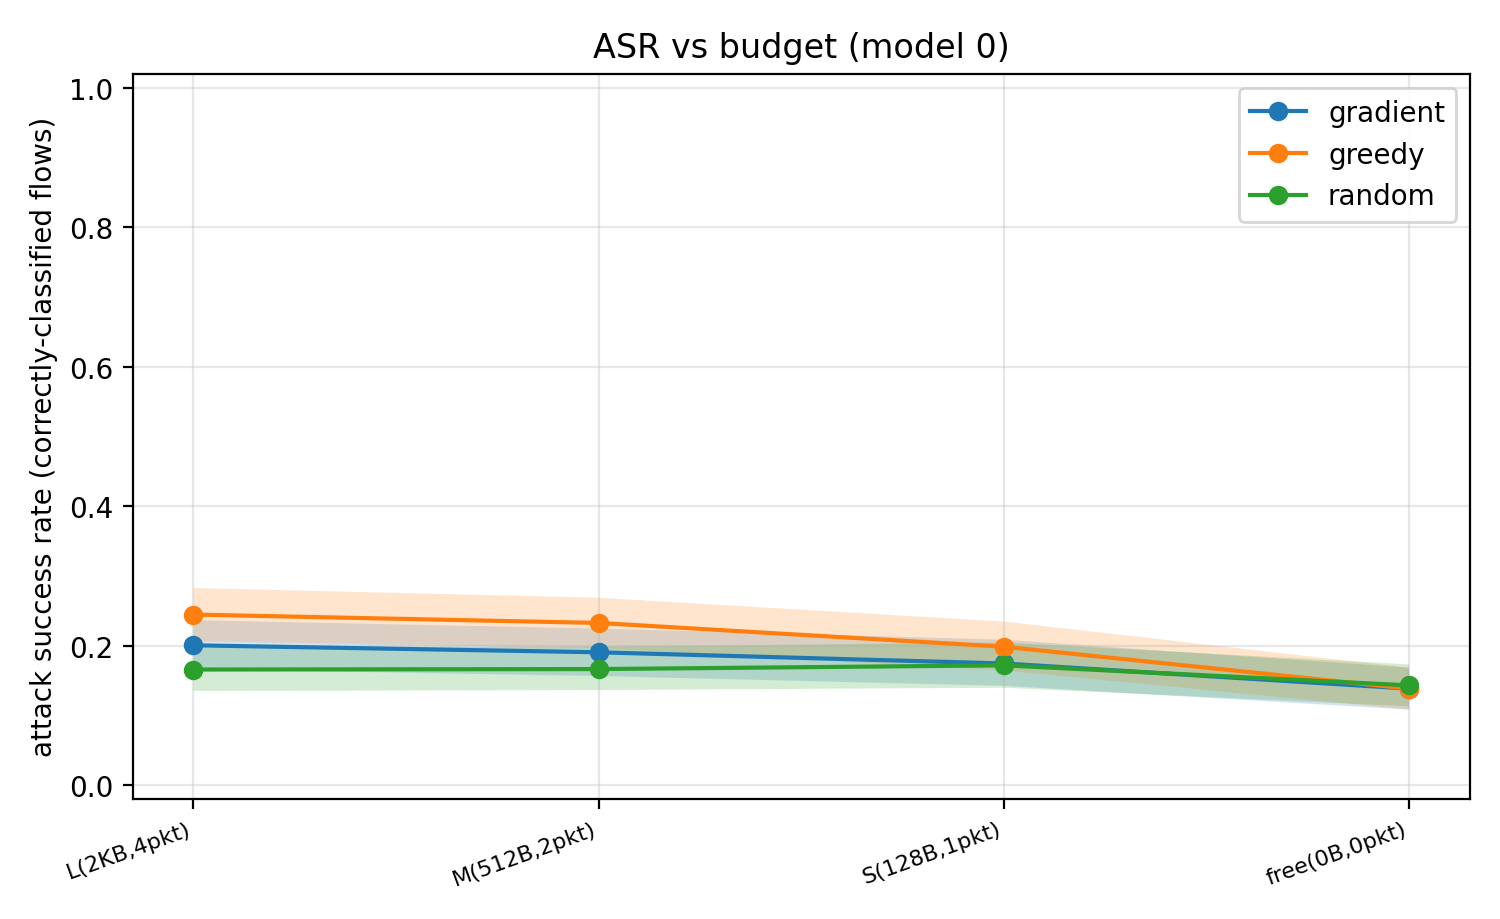

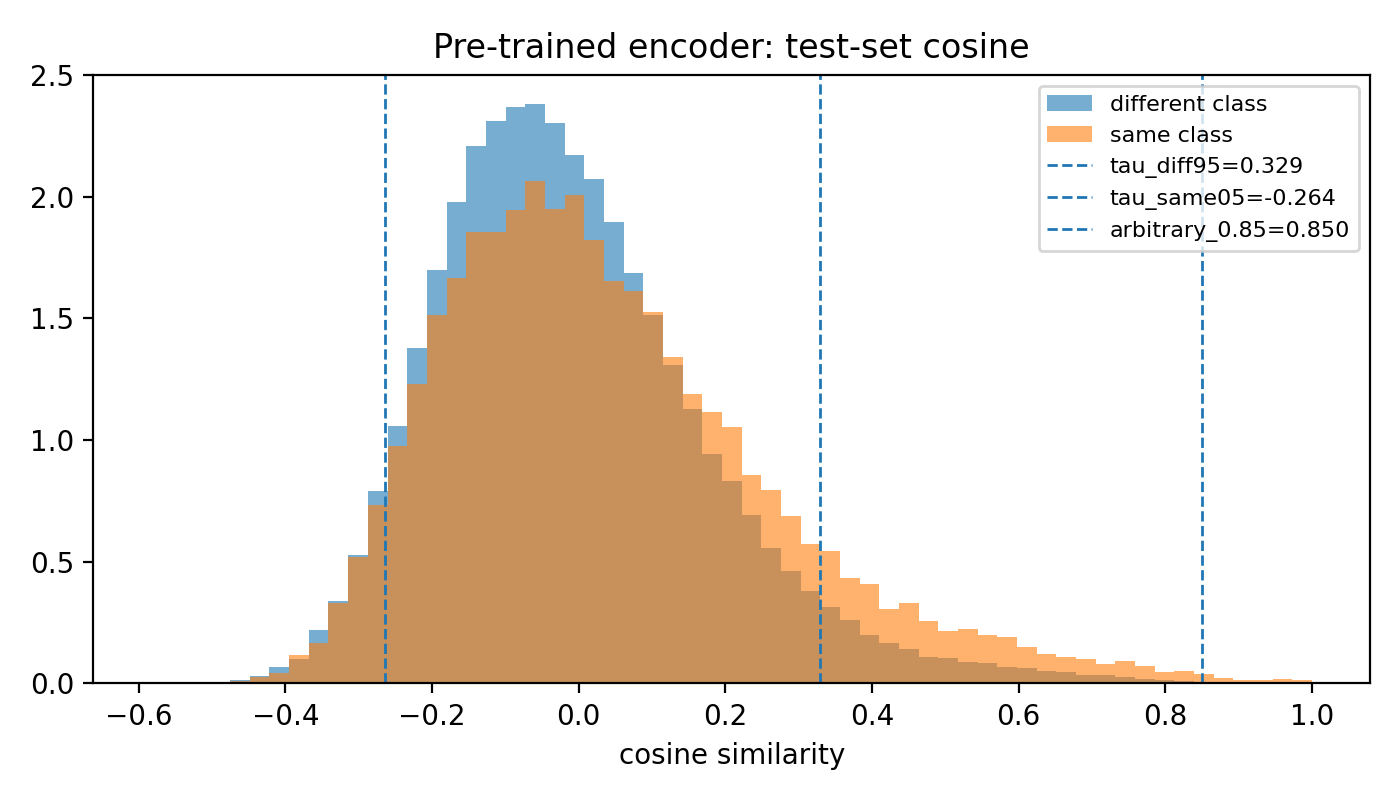

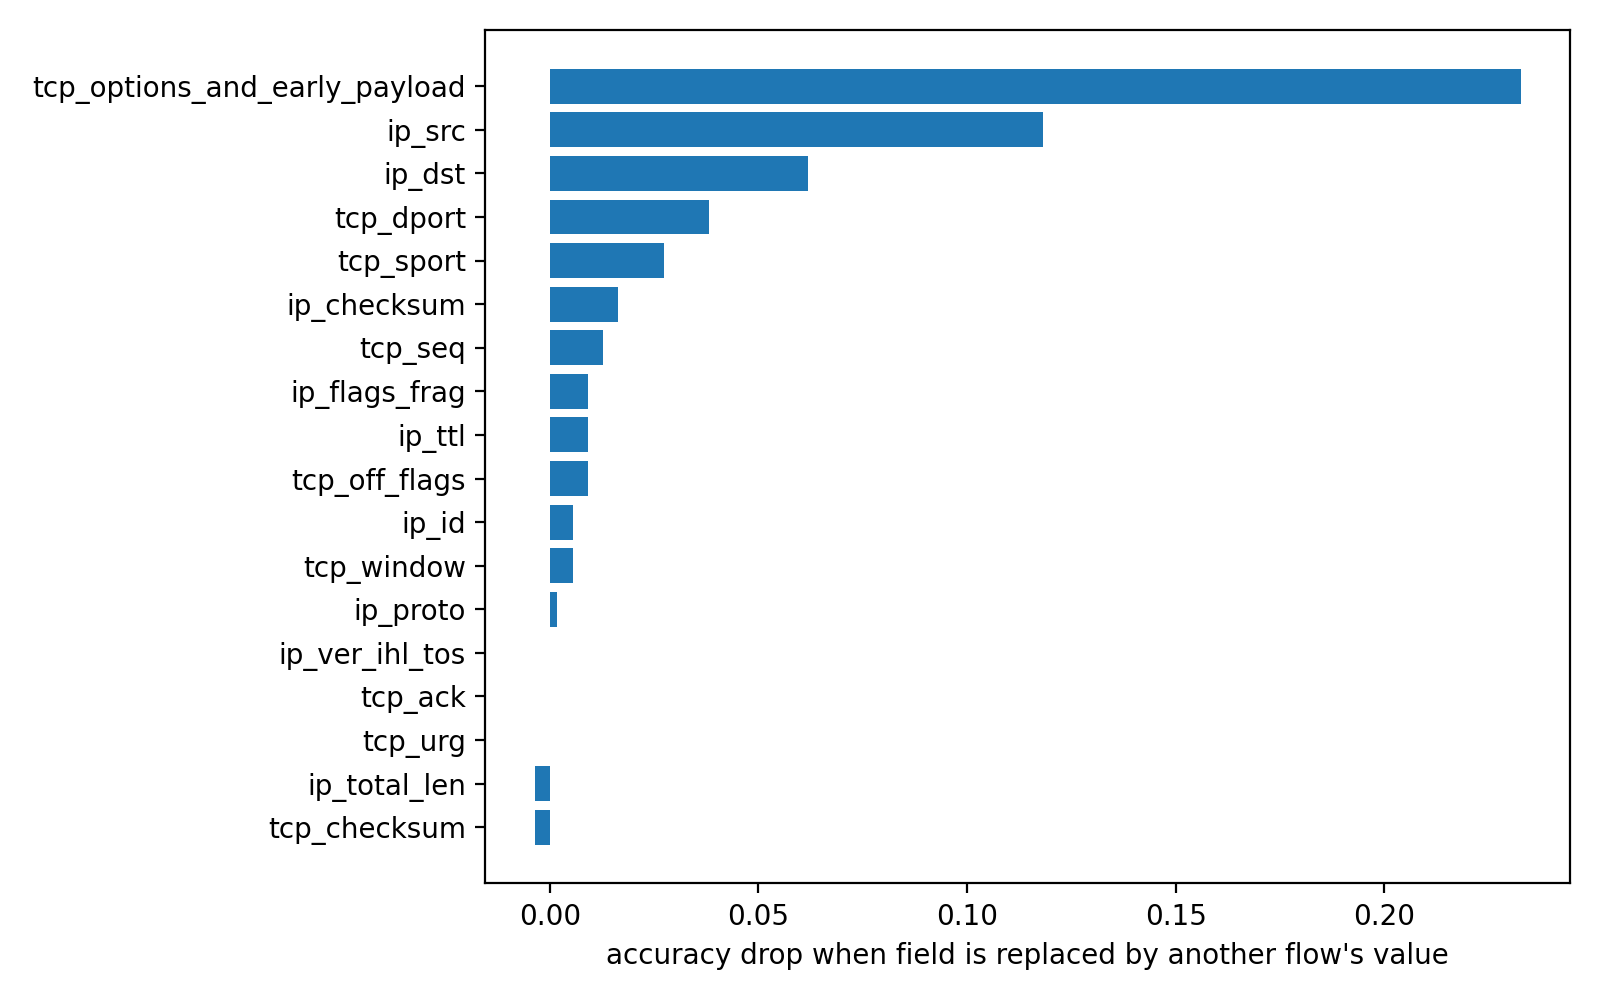

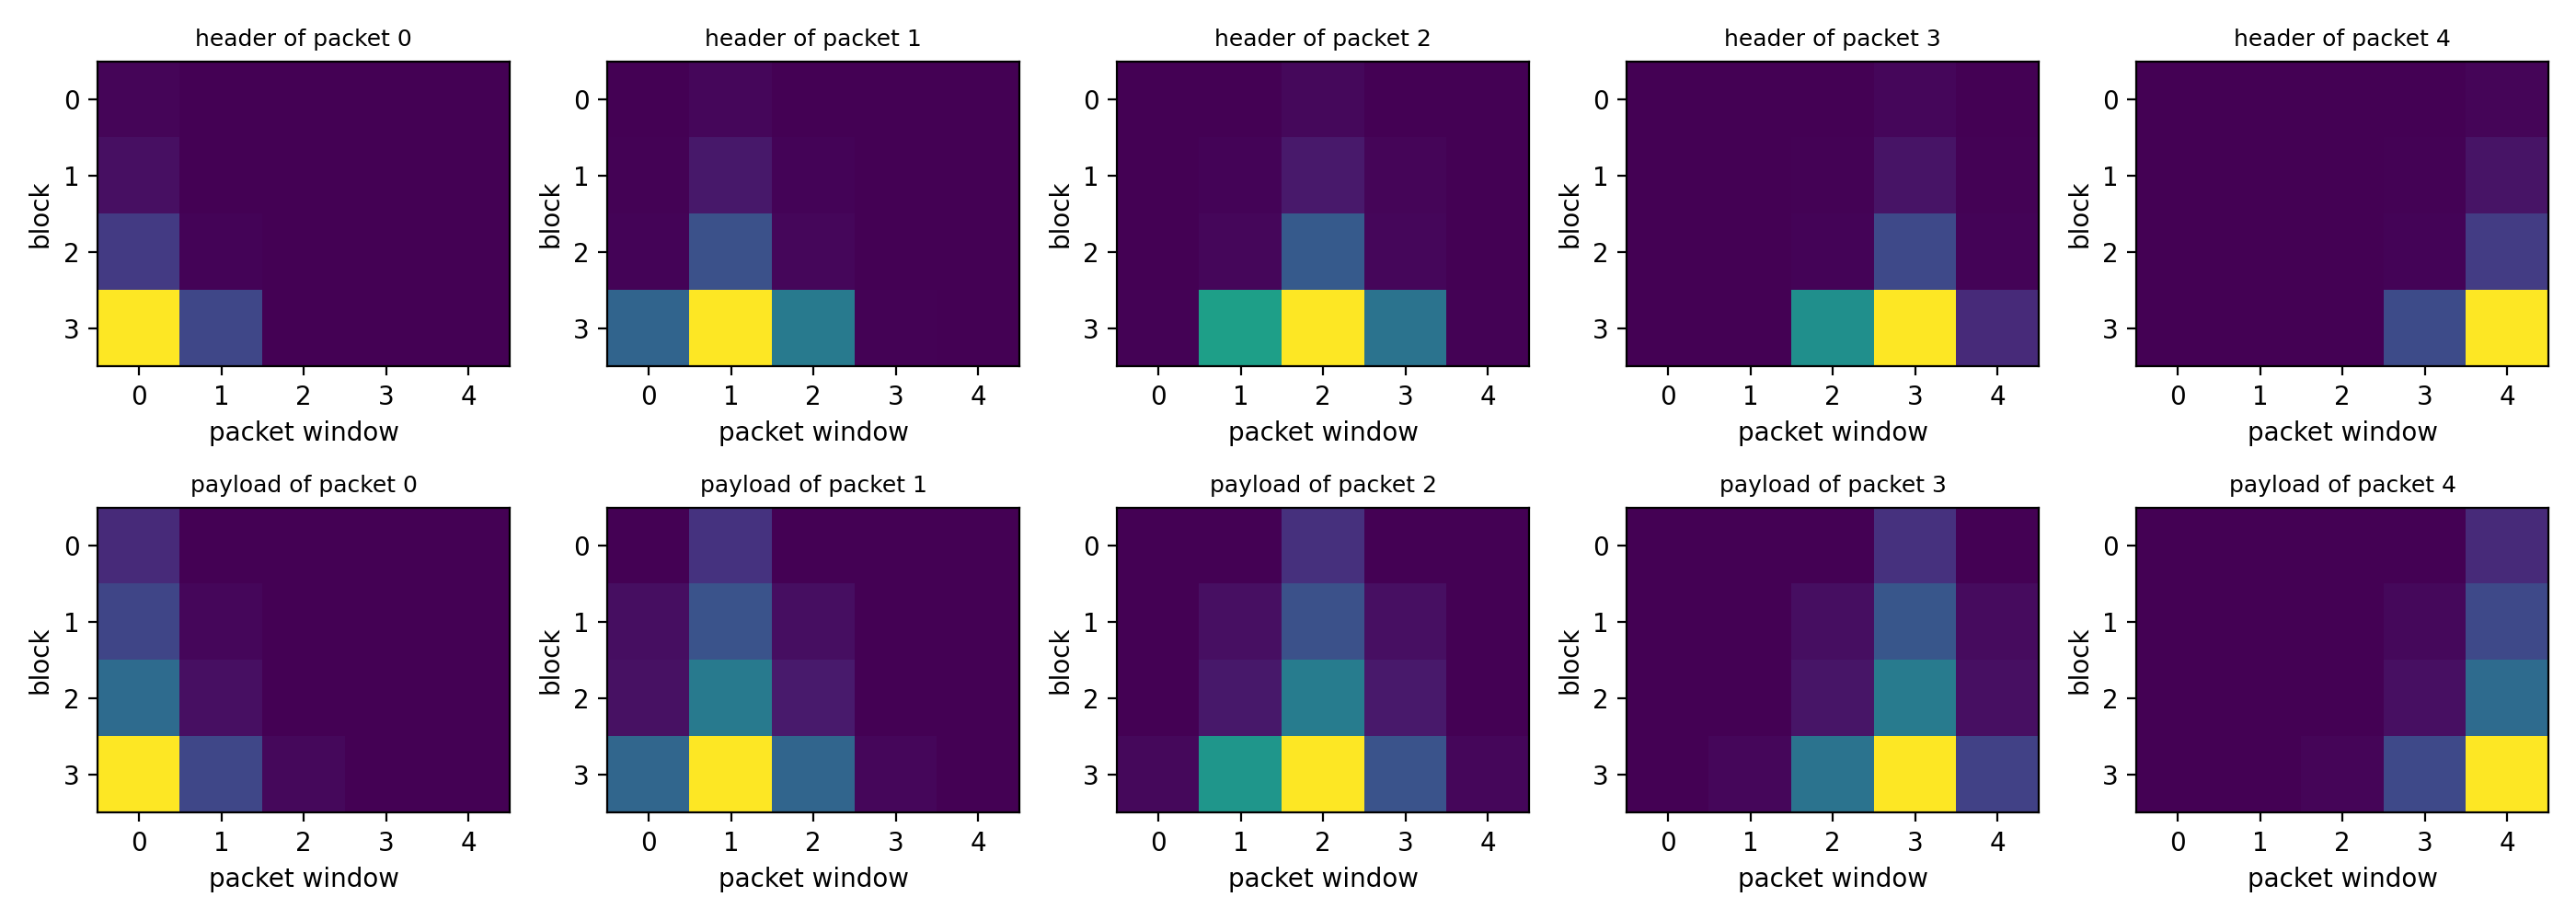


stage log:
  ('unit tests', 'ok', 14)
  ('finetune pre_seed0', 'ok', 290)
  ('finetune pre_seed1', 'ok', 251)
  ('finetune pre_seed2', 'ok', 250)
  ('finetune scratch_seed0', 'ok', 252)
  ('finetune pre_cd', 'ok', 221)
  ('finetune pre_masked', 'ok', 251)
  ('finetune pre_masked_cd', 'ok', 222)
  ('finetune pre_masked_ip', 'ok', 254)
  ('linear probe (pretrained vs random-init vs fine-tuned)', 'ok', 18)
  ('evasion main', 'ok', 3139)
  ('evasion other training seeds (greedy only)', 'ok', 797)
  ('matched: pretrained vs scratch', 'ok', 2305)
  ('impersonation', 'ok', 943)
  ('capture-disjoint (unmasked)', 'ok', 1412)
  ('masked, convention split', 'ok', 1107)
  ('masked IP addresses only', 'ok', 1267)
  ('masked, capture-disjoint', 'ok', 938)
  ('shortcut audit', 'ok', 135)
  ('window groups', 'ok', 18)
  ('rq1 raw cosine', 'ok', 122)
  ('rq1 centred cosine', 'ok', 132)
  ('foundation transfer', 'ok', 147)
  ('adversarial fine-tuning + adaptive attack', 'ok', 2337)


[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

In [13]:
# ── CELL 13: consolidated results ─────────────────────────────────────
import pandas as pd
from IPython.display import display, Image
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

def merged(name):
    f = OUT / name / "merged.json"
    return json.load(open(f)) if f.exists() else None

story = []
for label, d in [("pretrained, convention split", "evasion"), ("pretrained (matched set)", "matched_pre"),
                 ("scratch (matched set)", "matched_scratch"), ("pretrained, capture-disjoint", "capdisjoint"),
                 ("pretrained, IP/port-masked", "masked"), ("pretrained, IP-address-masked only", "masked_ip"), ("masked + capture-disjoint", "masked_capdisjoint"),
                 ("impersonation (pretrained)", "impersonation")]:
    m = merged(d)
    if not m: continue
    info = m["models"].get("0", m["models"].get(0, {}))
    for r in m["rows"]:
        if r["model"] == 0 and r["attack"] in ("greedy", "random") and r["budget"] in ("free(0B,0pkt)", "L(2KB,4pkt)"):
            story.append(dict(setting=label, attack=r["attack"], budget=r["budget"],
                              clean_acc=round(info.get("clean_acc", float("nan")), 3), n_attacked=r["n_flows"],
                              asr=round(r["asr"], 3), ci=f"[{r['lo']:.3f}, {r['hi']:.3f}]"))
story_df = pd.DataFrame(story)
display(story_df)
story_df.to_csv(OUT / "story_table.csv", index=False)

for name in ("evasion",):
    f = OUT / name / "merged.csv"
    if f.exists():
        print("\n== full", name); display(pd.read_csv(f)[["model", "attack", "budget", "asr", "lo", "hi", "n_flows", "robust_acc_all_flows"]])
for f in ["paired_pre_vs_scratch.csv"]:
    if (OUT / f).exists(): print("\n== paired pretrained vs scratch"); display(pd.read_csv(OUT / f))
for f in ["linear_probe/linear_probe.json", "rq1_raw/rq1_calibrated.json", "rq1_centered/rq1_calibrated.json",
          "foundation/foundation_transfer.json"]:
    if (OUT / f).exists(): print("\n==", f); print(json.dumps(json.load(open(OUT / f)), indent=1, default=str)[:2200])
sc = OUT / "shortcut" / "shortcut_fields.json"
if sc.exists():
    s = json.load(open(sc)); print("\n== shortcut audit, clean acc", round(s["base_acc"], 3))
    display(pd.DataFrame(s["fields"])[["field", "acc_zero", "acc_shuffle", "attribution_share"]].round(3))
for img in [OUT / "evasion" / "asr_vs_budget_model0.png", OUT / "rq1_centered" / "cosine_distributions.png",
            OUT / "shortcut" / "shortcut_fields.png", OUT / "windows" / "window_drift_heatmaps.png"]:
    if img.exists(): display(Image(str(img)))
print("\nstage log:"); [print(" ", x) for x in STAGE_LOG]

In [14]:
# ── CELL 14: final bundle ─────────────────────────────────────────────
bundle()
print("download: /kaggle/working/taco_robust_results.zip")
if FAST:
    print("WARNING: FAST=True - these are smoke-run numbers on 100 flows / 12 epochs; set FAST=False for the real results.")
print("stage summary:", [(n, s) for n, s, _ in STAGE_LOG])

download: /kaggle/working/taco_robust_results.zip
stage summary: [('unit tests', 'ok'), ('finetune pre_seed0', 'ok'), ('finetune pre_seed1', 'ok'), ('finetune pre_seed2', 'ok'), ('finetune scratch_seed0', 'ok'), ('finetune pre_cd', 'ok'), ('finetune pre_masked', 'ok'), ('finetune pre_masked_cd', 'ok'), ('finetune pre_masked_ip', 'ok'), ('linear probe (pretrained vs random-init vs fine-tuned)', 'ok'), ('evasion main', 'ok'), ('evasion other training seeds (greedy only)', 'ok'), ('matched: pretrained vs scratch', 'ok'), ('impersonation', 'ok'), ('capture-disjoint (unmasked)', 'ok'), ('masked, convention split', 'ok'), ('masked IP addresses only', 'ok'), ('masked, capture-disjoint', 'ok'), ('shortcut audit', 'ok'), ('window groups', 'ok'), ('rq1 raw cosine', 'ok'), ('rq1 centred cosine', 'ok'), ('foundation transfer', 'ok'), ('adversarial fine-tuning + adaptive attack', 'ok')]
